# Exercise 1:  
Write a program using numpy lib to calculate: 
- the multiplication of two given matrixes
- the outer product of two given vectors
- the cross product of two given vectors
- the determinant of a given square array
- the determinant of an array
- the inner product of vectors for 1-D arrays (without complex conjugation) and in 
higher dimension

In [4]:
import numpy as np

A = np.random.randint(-9, 9, (3, 3))
B = np.random.randint(-9, 9, (3, 3))

# vector mẫu cho các phép tích vector
u = np.random.randint(-9, 9, 3)
v = np.random.randint(-9, 9, 3)

print(f'''
A = {A}

B = {B}

multiplication (matrix product A @ B):
{A @ B}

u = {u}

v = {v}

outer product (u ⊗ v):
{np.outer(u, v)}

cross product (u × v):
{np.cross(u, v)}

determinant of a given square array A:
{np.linalg.det(A)}

determinant of an array B:
{np.linalg.det(B)}

inner product:
- 1D vectors ⟨u, v⟩: {np.inner(u, v)}

- higher dimension inner product (A, B):
{np.inner(A, B)}
''')



A = [[ 3  5  4]
 [ 2 -5 -3]
 [ 1  0 -3]]

B = [[-2  8  7]
 [ 8  5 -5]
 [ 2 -6  6]]

multiplication (matrix product A @ B):
[[ 42  25  20]
 [-50   9  21]
 [ -8  26 -11]]

u = [-2  6 -4]

v = [ 7 -1  7]

outer product (u ⊗ v):
[[-14   2 -14]
 [ 42  -6  42]
 [-28   4 -28]]

cross product (u × v):
[ 38 -14 -40]

determinant of a given square array A:
80.00000000000004

determinant of an array B:
-869.9999999999994

inner product:
- 1D vectors ⟨u, v⟩: -48

- higher dimension inner product (A, B):
[[ 62  29   0]
 [-65   6  16]
 [-23  23 -16]]



# Exercise 2:  
## 2.1 Build a Stack with the framework as follows:
```python
    class Stack: 
        def __init__(self): 
            self.st = [] 
        def push(self,el): 
        def pop(self): 
        def isEmpty(self): 
        def size(self): 
        def top(self): 
    if __name__ == '__main__': 
        st = Stack()    
        st.push(5) 
        st.push(7) 
        st.push(9) 
        print(st.pop()) 
        print(st.top()) 
```
## 2.2 Using Stack above to convert a number in Decimal to Binary. 
    Example: Input: 10, Output: 1010 

In [52]:
# 2.1
class Stack:
    def __init__(self):
        self.st = []
    def push(self, el):
        self.st.append(el)
    def pop(self):
        if self.isEmpty()==False:
            x = self.st[len(self.st)-1]
            self.st.remove(x)
            return x
        else:
            return None
    def isEmpty(self):
        return len(self.st)==0
    def size(self):
        return len(self.st)
    def top(self):
        if self.isEmpty()==False:
            return self.st[len(self.st)-1]
        else:
            return None
            
    def merge(self):
        self.st.reverse()
        return int(''.join(map(str, self.st)))
        
if __name__ == '__main__': 
    st = Stack()    
    st.push(5) 
    st.push(7) 
    st.push(9) 
    print(st.pop()) 
    print(st.top())  

9
7


In [44]:
# 2.2
def convert_dec2bin(dec):
    st = Stack()
    while dec>0:
        x = dec%2
        dec = dec//2
        st.push(x)
    return st.merge()

for i in range(10,15):
    print('Input: ',i)
    print('Output: ', convert_dec2bin(i))

Input:  10
Output:  1010
Input:  11
Output:  1011
Input:  12
Output:  1100
Input:  13
Output:  1101
Input:  14
Output:  1110


# Exercise 3: 
Write four functions to do + - * / for two big integers (hint: using Stack above)

Add(bigIntA, bigIntB) 

Sub(bigIntA, bigIntB) 

Mul(bigIntA, bigIntB) 

Div(bigIntA, bigIntB)

In [ ]:
def convert_num2arr(num, n_digits):
    st = Stack()
    n_digits-=1
    while num>0:
        st.append(num//10**n_digits)
        num %= 10**n_digits
        n_digits-=1
    return st
    
def Add(bigIntA, bigIntB):
    carry=0
    total = 0
    kq = Stack()
    while !bigIntA.isEmpty() | !bigIntB.isEmpty() | carry>0:
        total += bigIntA.pop()
        total += bigIntB.pop()
        total += carry

        kq.push(total%10)
        carry = total//10
        
    return kq.merge()

def Sub(bigIntA, bigIntB):
    borrow = 0
    sub = 0
    kq = Stack()
    
    while !bigIntA.isEmpty() | !bigIntB.isEmpty():
        a = bigIntA.pop() - borrow
        b = bigIntB.pop()
        if a>=b:
            sub = a-b
        else:
            sub = a+10-b
            borrow +=1
        kq.push(sub)
        
    return kq.merge()

def Mul(bigIntA, bigIntB):
    carry = 0
    total = 0
    kq = Stack()

    while bigIntA.isEmpty() | bigIntB.isEmpty() | carry>0:
        b = bigIntB.pop()
        A_tmp = Stack()
        
        while !bigIntA.isEmpty():
            a = bigIntA.pop()
            total = a*b + carry
            A_tmp.push(total%10)
            carry = total//10
        while !A_tmp:
            bigIntA.push(A_tmp.pop())
        
        total += bigIntA.pop()
        total += bigIntB.pop()
        total += carry

        kq.push(total%10)
        carry = total//10
        
    return kq.merge()

In [61]:
45//10

4

In [60]:
a=[1,2,3]
a.append(4)
a

[1, 2, 3, 4]

# Exercise 4: 
Complete Assignment 4 of MIT 6.0001 course 


## Part A

In [62]:
def get_permutations(sequence):
    '''
    Enumerate all permutations of a given string using recursion.
    '''
    # Base case: Nếu chuỗi chỉ có 1 ký tự
    if len(sequence) <= 1:
        return [sequence]

    # Recursive step
    first_char = sequence[0]
    remaining_chars = sequence[1:]
    
    # Lấy hoán vị của phần còn lại
    permutations_of_remainder = get_permutations(remaining_chars)
    all_permutations = []

    # Chèn ký tự đầu tiên vào mọi vị trí có thể của từng hoán vị con
    for char_set in permutations_of_remainder:
        for i in range(len(char_set) + 1):
            new_permutation = char_set[:i] + first_char + char_set[i:]
            if new_permutation not in all_permutations:
                all_permutations.append(new_permutation)

    return sorted(all_permutations)

if __name__ == '__main__':
    # Test case 1
    input1 = 'ab'
    print('Input:', input1)
    print('Expected Output:', ['ab', 'ba'])
    print('Actual Output:', get_permutations(input1))
    print('-' * 20)

    # Test case 2
    input2 = 'abc'
    print('Input:', input2)
    print('Expected Output:', ['abc', 'acb', 'bac', 'bca', 'cab', 'cba'])
    print('Actual Output:', get_permutations(input2))
    print('-' * 20)

    # Test case 3
    input3 = 'dog'
    print('Input:', input3)
    print('Expected Output:', ['dgo', 'dog', 'gdo', 'god', 'odg', 'ogd'])
    print('Actual Output:', get_permutations(input3))

Input: ab
Expected Output: ['ab', 'ba']
Actual Output: ['ab', 'ba']
--------------------
Input: abc
Expected Output: ['abc', 'acb', 'bac', 'bca', 'cab', 'cba']
Actual Output: ['abc', 'acb', 'bac', 'bca', 'cab', 'cba']
--------------------
Input: dog
Expected Output: ['dgo', 'dog', 'gdo', 'god', 'odg', 'ogd']
Actual Output: ['dgo', 'dog', 'gdo', 'god', 'odg', 'ogd']


## Part B

In [64]:
import string

### HELPER CODE (Giữ nguyên từ đề bài) ###
def load_words(file_name):
    print("Loading word list from file...")
    inFile = open(file_name, 'r')
    wordlist = []
    for line in inFile:
        wordlist.extend([word.lower() for word in line.split(' ')])
    print("  ", len(wordlist), "words loaded.")
    return wordlist

def is_word(word_list, word):
    word = word.lower()
    word = word.strip(" !@#$%^&*()-_+={}[]|\:;'<>?,./\"")
    return word in word_list

def get_story_string():
    f = open("story.txt", "r")
    story = str(f.read())
    f.close()
    return story

WORDLIST_FILENAME = 'words.txt'

### PHẦN THỰC HIỆN CỦA BẠN ###

class Message(object):
    def __init__(self, text):
        self.message_text = text
        self.valid_words = load_words(WORDLIST_FILENAME)

    def get_message_text(self):
        return self.message_text

    def get_valid_words(self):
        return self.valid_words[:]

    def build_shift_dict(self, shift):
        shift_dict = {}
        for alphabet in [string.ascii_lowercase, string.ascii_uppercase]:
            for i, char in enumerate(alphabet):
                shift_dict[char] = alphabet[(i + shift) % 26]
        return shift_dict

    def apply_shift(self, shift):
        shift_dict = self.build_shift_dict(shift)
        return "".join([shift_dict.get(char, char) for char in self.message_text])

class PlaintextMessage(Message):
    def __init__(self, text, shift):
        Message.__init__(self, text)
        self.shift = shift
        self.encryption_dict = self.build_shift_dict(shift)
        self.message_text_encrypted = self.apply_shift(shift)

    def get_shift(self):
        return self.shift

    def get_encryption_dict(self):
        return self.encryption_dict.copy()

    def get_message_text_encrypted(self):
        return self.message_text_encrypted

    def change_shift(self, shift):
        self.shift = shift
        self.encryption_dict = self.build_shift_dict(shift)
        self.message_text_encrypted = self.apply_shift(shift)

class CiphertextMessage(Message):
    def __init__(self, text):
        Message.__init__(self, text)

    def decrypt_message(self):
        max_valid_count = -1
        best_shift = 0
        best_text = ""
        
        for s in range(26):
            decoded_text = self.apply_shift(s)
            valid_count = sum(1 for word in decoded_text.split() if is_word(self.valid_words, word))
            if valid_count > max_valid_count:
                max_valid_count = valid_count
                best_shift = s
                best_text = decoded_text
        return (best_shift, best_text)

if __name__ == '__main__':
    # Test case PlaintextMessage 1
    p1 = PlaintextMessage('Hello World!', 2)
    print('Plaintext Test 1 - Input: Hello World!, Shift: 2')
    print('Expected: Jgnnq Yqtnf!, Actual:', p1.get_message_text_encrypted())

    # Test case PlaintextMessage 2
    p1.change_shift(4)
    print('Plaintext Test 2 - New Shift: 4')
    print('Expected: Lipps Asvph!, Actual:', p1.get_message_text_encrypted())

    # Test case CiphertextMessage 1
    c1 = CiphertextMessage('Lipps Asvph!')
    print('Ciphertext Test 1 - Input: Lipps Asvph!')
    print('Expected: (22, "Hello World!"), Actual:', c1.decrypt_message())

    # Test case CiphertextMessage 2
    c2 = CiphertextMessage('khoor')
    print('Ciphertext Test 2 - Input: khoor')
    print('Expected: (23, "hello"), Actual:', c2.decrypt_message())

    # Giải mã story.txt
    story_encrypted = get_story_string()
    cipher_story = CiphertextMessage(story_encrypted)
    best_shift, decrypted_story = cipher_story.decrypt_message()
    print('\nDecrypted Story Shift:', best_shift)
    print('Decrypted Story:', decrypted_story)

<>:15: SyntaxWarning: invalid escape sequence '\:'
<>:15: SyntaxWarning: invalid escape sequence '\:'
C:\Users\Itel\AppData\Local\Temp\ipykernel_16372\4161036601.py:15: SyntaxWarning: invalid escape sequence '\:'
  word = word.strip(" !@#$%^&*()-_+={}[]|\:;'<>?,./\"")


Loading word list from file...
   55901 words loaded.
Plaintext Test 1 - Input: Hello World!, Shift: 2
Expected: Jgnnq Yqtnf!, Actual: Jgnnq Yqtnf!
Plaintext Test 2 - New Shift: 4
Expected: Lipps Asvph!, Actual: Lipps Asvph!
Loading word list from file...
   55901 words loaded.
Ciphertext Test 1 - Input: Lipps Asvph!
Expected: (22, "Hello World!"), Actual: (22, 'Hello World!')
Loading word list from file...
   55901 words loaded.
Ciphertext Test 2 - Input: khoor
Expected: (23, "hello"), Actual: (23, 'hello')
Loading word list from file...
   55901 words loaded.

Decrypted Story Shift: 12
Decrypted Story: Jack Florey is a mythical character created on the spur of a moment to help cover an insufficiently planned hack. He has been registered for classes at MIT twice before, but has reportedly never passed aclass. It has been the tradition of the residents of East Campus to become Jack Florey for a few nights each year to educate incoming students in the ways, means, and ethics of hacking.

## Part C

In [66]:
import string

### HELPER CODE (Giữ nguyên) ###
def load_words(file_name):
    inFile = open(file_name, 'r')
    wordlist = []
    for line in inFile:
        wordlist.extend([word.lower() for word in line.split(' ')])
    return wordlist

def is_word(word_list, word):
    word = word.lower().strip(" !@#$%^&*()-_+={}[]|\:;'<>?,./\"")
    return word in word_list

WORDLIST_FILENAME = 'words.txt'
VOWELS_LOWER = 'aeiou'
VOWELS_UPPER = 'AEIOU'
CONSONANTS_LOWER = 'bcdfghjklmnpqrstvwxyz'
CONSONANTS_UPPER = 'BCDFGHJKLMNPQRSTVWXYZ'

### PHẦN THỰC HIỆN ###

class SubMessage(object):
    def __init__(self, text):
        self.message_text = text
        self.valid_words = load_words(WORDLIST_FILENAME)
    
    def get_message_text(self):
        return self.message_text

    def get_valid_words(self):
        return self.valid_words[:]
                
    def build_transpose_dict(self, vowels_permutation):
        transpose_dict = {}
        # Giữ nguyên phụ âm
        for char in CONSONANTS_LOWER + CONSONANTS_UPPER:
            transpose_dict[char] = char
        # Thay thế nguyên âm theo hoán vị
        for i, v in enumerate(VOWELS_LOWER):
            transpose_dict[v] = vowels_permutation[i].lower()
            transpose_dict[VOWELS_UPPER[i]] = vowels_permutation[i].upper()
        return transpose_dict
    
    def apply_transpose(self, transpose_dict):
        return "".join([transpose_dict.get(char, char) for char in self.message_text])
        
class EncryptedSubMessage(SubMessage):
    def __init__(self, text):
        SubMessage.__init__(self, text)

    def decrypt_message(self):
        vowel_perms = get_permutations(VOWELS_LOWER)
        max_words = -1
        best_message = self.message_text
        
        for perm in vowel_perms:
            transpose_dict = self.build_transpose_dict(perm)
            decrypted_text = self.apply_transpose(transpose_dict)
            # Đếm số từ hợp lệ
            word_count = sum(1 for word in decrypted_text.split() if is_word(self.valid_words, word))
            
            if word_count > max_words:
                max_words = word_count
                best_message = decrypted_text
                
        return best_message

if __name__ == '__main__':
    # Test Case 1: SubMessage
    msg1 = SubMessage("Hello World!")
    perm1 = "eaiuo"
    print("Test SubMessage 1 - Input: Hello World!, Perm: eaiuo")
    print("Expected: Hallu Wurld!, Actual:", msg1.apply_transpose(msg1.build_transpose_dict(perm1)))

    # Test Case 2: SubMessage
    msg2 = SubMessage("Python is fun")
    perm2 = "uoiea"
    print("\nTest SubMessage 2 - Input: Python is fun, Perm: uoiea")
    print("Actual:", msg2.apply_transpose(msg2.build_transpose_dict(perm2)))

    # Test Case 3: EncryptedSubMessage
    enc_msg1 = EncryptedSubMessage("Hallu Wurld!")
    print("\nTest Decrypt 1 - Input: Hallu Wurld!")
    print("Expected: Hello World!, Actual:", enc_msg1.decrypt_message())

    # Test Case 4: EncryptedSubMessage
    # "Apple" với hoán vị "eaiuo" (a->e, e->a) thành "Eppla"
    enc_msg2 = EncryptedSubMessage("Eppla")
    print("\nTest Decrypt 2 - Input: Eppla")
    print("Expected: Apple, Actual:", enc_msg2.decrypt_message())

<>:12: SyntaxWarning: invalid escape sequence '\:'
<>:12: SyntaxWarning: invalid escape sequence '\:'
C:\Users\Itel\AppData\Local\Temp\ipykernel_16372\2506507569.py:12: SyntaxWarning: invalid escape sequence '\:'
  word = word.lower().strip(" !@#$%^&*()-_+={}[]|\:;'<>?,./\"")


Test SubMessage 1 - Input: Hello World!, Perm: eaiuo
Expected: Hallu Wurld!, Actual: Hallu Wurld!

Test SubMessage 2 - Input: Python is fun, Perm: uoiea
Actual: Pythen is fan

Test Decrypt 1 - Input: Hallu Wurld!
Expected: Hello World!, Actual: Hello World!

Test Decrypt 2 - Input: Eppla
Expected: Apple, Actual: Apple


# Exercise 5: 
Complete Assignment 5 of MIT 6.0001 course

In [15]:
import feedparser
import string
import time
import threading
from project_util import translate_html
from mtTkinter import *
from datetime import datetime
import pytz

import collections
if not hasattr(collections, 'Callable'):
    import collections.abc
    collections.Callable = collections.abc.Callable

#-----------------------------------------------------------------------

#======================
# Code for retrieving and parsing
# Google and Yahoo News feeds
# Do not change this code
#======================

def process(url):
    """
    Fetches news items from the rss url and parses them.
    Returns a list of NewsStory-s.
    """
    import ssl
    if hasattr(ssl, '_create_unverified_context'):
        ssl._create_default_https_context = ssl._create_unverified_context

    feed = feedparser.parse(url)
    entries = feed.entries
    ret = []
    for entry in entries:
       
        guid = entry.get('guid', entry.get('link', 'No GUID'))
        title = translate_html(entry.get('title', 'No Title'))
        link = entry.get('link', '#')
        
        
        description = entry.get('description', entry.get('summary', 'No description available'))
        description = translate_html(description)
        
        pubdate = entry.get('published', entry.get('pubDate', ''))
        
        if pubdate:
            pubdate = translate_html(pubdate)
            try:
                # Thử parse định dạng GMT
                pubdate = datetime.strptime(pubdate, "%a, %d %b %Y %H:%M:%S %Z")
                pubdate = pubdate.replace(tzinfo=pytz.timezone("GMT"))
            except ValueError:
                try:
                    # Thử định dạng có offset (+0000)
                    pubdate = datetime.strptime(pubdate, "%a, %d %b %Y %H:%M:%S %z")
                except ValueError:
                    # Nếu không parse được, lấy thời gian hiện tại
                    pubdate = datetime.now().replace(tzinfo=pytz.timezone("GMT"))
        else:
            pubdate = datetime.now().replace(tzinfo=pytz.timezone("GMT"))

        newsStory = NewsStory(guid, title, description, link, pubdate)
        ret.append(newsStory)
    return ret

In [3]:
# Problem 1

class NewsStory(object):
    def __init__(self, guid, title, description, link, pubdate):
        self.guid = guid
        self.title = title
        self.description = description
        self.link = link
        self.pubdate = pubdate

    def get_guid(self):
        return self.guid

    def get_title(self):
        return self.title

    def get_description(self):
        return self.description

    def get_link(self):
        return self.link

    def get_pubdate(self):
        return self.pubdate

#======================
# Triggers
#======================

class Trigger(object):
    def evaluate(self, story):
        """
        Returns True if an alert should be generated
        for the given news item, or False otherwise.
        """
        # DO NOT CHANGE THIS!
        raise NotImplementedError

In [4]:
# Problem 2
class PhraseTrigger(Trigger):
    def __init__(self, phrase):
        self.phrase = phrase.lower()

    def is_phrase_in(self, text):
        # Chuyển text về chữ thường
        clean_text = text.lower()
        # Thay thế toàn bộ dấu câu bằng khoảng trắng
        for char in string.punctuation:
            clean_text = clean_text.replace(char, ' ')
        
        # Tách từ để loại bỏ khoảng trắng thừa
        text_words = clean_text.split()
        phrase_words = self.phrase.split()
        
        # Kiểm tra xem cụm từ có xuất hiện đúng thứ tự trong văn bản không
        for i in range(len(text_words) - len(phrase_words) + 1):
            if text_words[i : i + len(phrase_words)] == phrase_words:
                return True
        return False

In [5]:
# Problem 3
class TitleTrigger(PhraseTrigger):
    def evaluate(self, story):
        # Sử dụng is_phrase_in để kiểm tra tiêu đề của NewsStory
        return self.is_phrase_in(story.get_title())

In [6]:
# Problem 4
class DescriptionTrigger(PhraseTrigger):
    def evaluate(self, story):
        # Sử dụng is_phrase_in để kiểm tra mô tả của NewsStory
        return self.is_phrase_in(story.get_description())

In [7]:
# Problem 5
class TimeTrigger(Trigger):
    def __init__(self, time_str):
        # Định dạng: "3 Oct 2016 17:00:10"
        time_format = "%d %b %Y %H:%M:%S"
        # Chuyển string thành datetime và gán múi giờ EST
        self.trigger_time = datetime.strptime(time_str, time_format).replace(tzinfo=pytz.timezone("EST"))

In [8]:
# Problem 6
class BeforeTrigger(TimeTrigger):
    def evaluate(self, story):
        story_time = story.get_pubdate()
        # Đảm bảo story_time có thông tin timezone để so sánh
        if story_time.tzinfo is None:
            story_time = story_time.replace(tzinfo=pytz.timezone("EST"))
        # Trả về True nếu xuất bản TRƯỚC thời gian trigger
        return story_time < self.trigger_time

class AfterTrigger(TimeTrigger):
    def evaluate(self, story):
        story_time = story.get_pubdate()
        # Đảm bảo story_time có thông tin timezone để so sánh
        if story_time.tzinfo is None:
            story_time = story_time.replace(tzinfo=pytz.timezone("EST"))
        # Trả về True nếu xuất bản SAU thời gian trigger
        return story_time > self.trigger_time

In [9]:
# Problem 7
class NotTrigger(Trigger):
    def __init__(self, trigger):
        self.trigger = trigger

    def evaluate(self, story):
        return not self.trigger.evaluate(story)

In [10]:
# Problem 8
class AndTrigger(Trigger):
    def __init__(self, trig1, trig2):
        self.trig1 = trig1
        self.trig2 = trig2

    def evaluate(self, story):
        return self.trig1.evaluate(story) and self.trig2.evaluate(story)

In [11]:
# Problem 9
class OrTrigger(Trigger):
    def __init__(self, trig1, trig2):
        self.trig1 = trig1
        self.trig2 = trig2

    def evaluate(self, story):
        return self.trig1.evaluate(story) or self.trig2.evaluate(story)

In [12]:
# Problem 10
def filter_stories(stories, triggerlist):
    filtered_stories = []
    for story in stories:
        # Nếu bất kỳ trigger nào trong danh sách trả về True, giữ lại bài báo đó
        if any(trigger.evaluate(story) for trigger in triggerlist):
            filtered_stories.append(story)
    return filtered_stories

In [13]:
# Problem 11
def read_trigger_config(filename):
    trigger_file = open(filename, 'r')
    lines = [line.rstrip() for line in trigger_file if not (len(line.rstrip()) == 0 or line.startswith('//'))]
    
    triggers_dict = {}
    trigger_list = []

    for line in lines:
        parts = line.split(',')
        
        if parts[0] == 'ADD':
            for name in parts[1:]:
                trigger_list.append(triggers_dict[name])
        else:
            t_name = parts[0]
            t_type = parts[1]
            
            if t_type == 'TITLE':
                triggers_dict[t_name] = TitleTrigger(parts[2])
            elif t_type == 'DESCRIPTION':
                triggers_dict[t_name] = DescriptionTrigger(parts[2])
            elif t_type == 'AFTER':
                triggers_dict[t_name] = AfterTrigger(parts[2])
            elif t_type == 'BEFORE':
                triggers_dict[t_name] = BeforeTrigger(parts[2])
            elif t_type == 'NOT':
                triggers_dict[t_name] = NotTrigger(triggers_dict[parts[2]])
            elif t_type == 'AND':
                triggers_dict[t_name] = AndTrigger(triggers_dict[parts[2]], triggers_dict[parts[3]])
            elif t_type == 'OR':
                triggers_dict[t_name] = OrTrigger(triggers_dict[parts[2]], triggers_dict[parts[3]])

    return trigger_list

In [17]:
SLEEPTIME = 60 #seconds -- how often we poll

def main_thread(master, title_var, cont):
    # A sample trigger list - you might need to change the phrases to correspond
    # to what is currently in the news
    guidShown = []
    try:
        t1 = TitleTrigger("election")
        t2 = DescriptionTrigger("Trump")
        t3 = DescriptionTrigger("Clinton")
        t4 = AndTrigger(t2, t3)
        triggerlist = [t1, t4]

        # Problem 11
        # TODO: After implementing read_trigger_config, uncomment this line 
        triggerlist = read_trigger_config('triggers.txt')
        
        def get_cont(newstory):
            if newstory.get_guid() not in guidShown:
                cont.insert(END, newstory.get_title()+"\n", "title")
                cont.insert(END, "\n---------------------------------------------------------------\n", "title")
                cont.insert(END, newstory.get_description())
                cont.insert(END, "\n*********************************************************************\n", "title")
                guidShown.append(newstory.get_guid())
        while True:

            print("Polling . . .", end=' ')
            # Get stories from Google's Top Stories RSS news feed
            stories = process("http://news.google.com/news?output=rss")
        
            # Get stories from Yahoo's Top Stories RSS news feed
            stories.extend(process("http://news.yahoo.com/rss/topstories"))
           
            stories = filter_stories(stories, triggerlist)

            list(map(get_cont, stories))
            scrollbar.config(command=cont.yview)


            print("Sleeping...")
            time.sleep(SLEEPTIME)

    except Exception as e:
        print(e)


if __name__ == '__main__':
    root = Tk()
    root.title("Some RSS parser")
    
    t_str = "Google & Yahoo Top News"
    title_var = StringVar(root, value=t_str)
    ttl = Label(root, textvariable=title_var, font=("Helvetica", 18))
    ttl.pack(side=TOP)
    
    scrollbar = Scrollbar(root)
    scrollbar.pack(side=RIGHT, fill=Y)
    
    cont_widget = Text(root, font=("Helvetica", 14), yscrollcommand=scrollbar.set)
    cont_widget.pack(side=BOTTOM)
    cont_widget.tag_config("title", justify='center')
    
    scrollbar.config(command=cont_widget.yview)

    t = threading.Thread(target=main_thread, args=(root, title_var, cont_widget))
    t.start()
    
    root.mainloop()

Polling . . . Sleeping...
Polling . . . 

## Output:
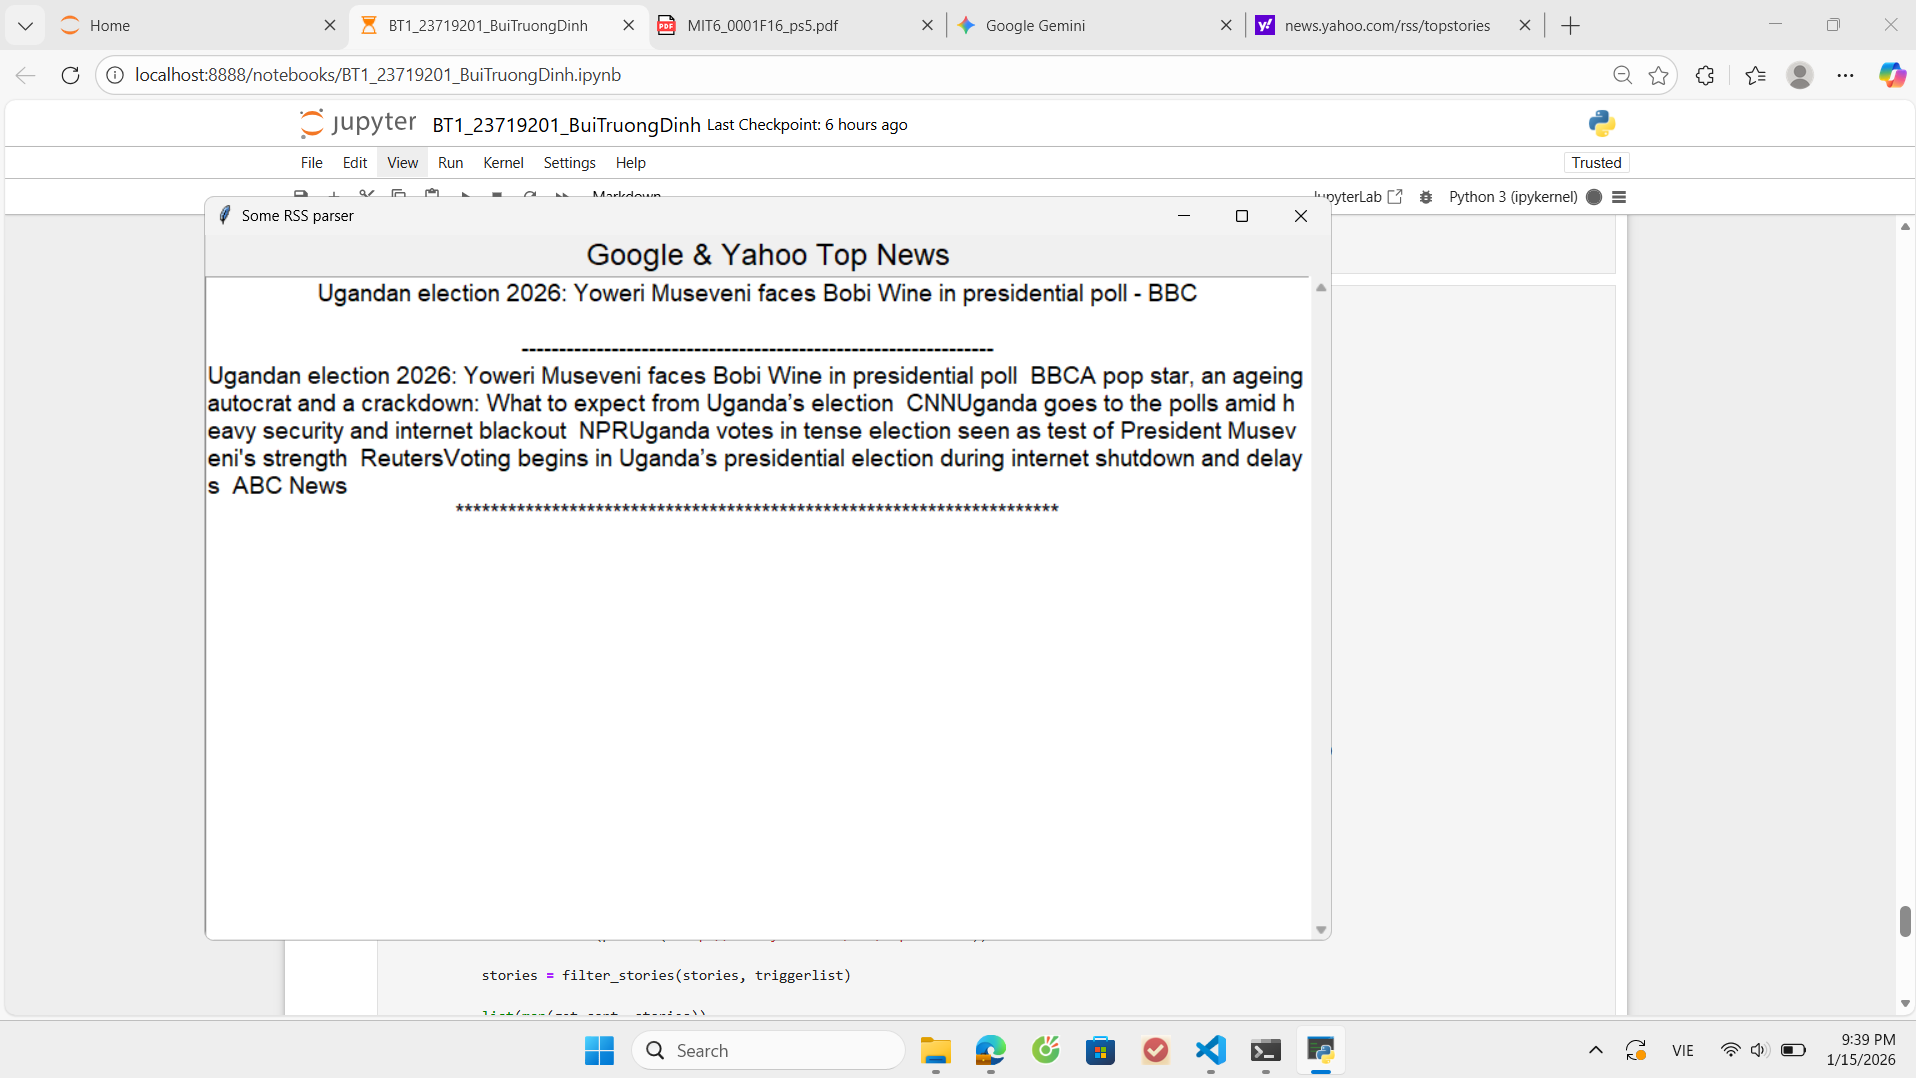

### Problem 12
```text
// Định nghĩa các trigger thời gian
t1,AFTER,15 Jan 2026 18:00:00
t2,BEFORE,16 Jan 2026 00:00:00
time_window,AND,t1,t2

// Định nghĩa từ khóa
t3,TITLE,debate
t4,DESCRIPTION,president
t5,OR,t3,t4

// Kết hợp: Phải có từ khóa VÀ nằm trong khung giờ
final_trigger,AND,time_window,t5

// Thêm vào danh sách lọc
ADD,final_trigger
```